# Baseline Model Training – Machine Failure Prediction (AI4I 2020)

## Objective
Train and compare baseline classification models to predict **Machine failure** using the cleaned dataset.
Because the dataset is imbalanced, evaluation focuses on **PR-AUC**, **Recall**, and **F1-score**.

The outcome of this notebook will be:
- Best baseline model selection
- Feature engineering improvement verification
- Threshold optimization (decision rule)
- Risk tiers (Low / Medium / High)
- Saved model artifact for explainability and Streamlit deployment


In [1]:
# Import numerical computing library
import numpy as np

# Import data manipulation library
import pandas as pd

# Import plotting library
import matplotlib.pyplot as plt

# Import model saving/loading utility
import joblib

# Import system utilities
import sys
from pathlib import Path

# Import plotting library again (already imported above)
import matplotlib.pyplot as plt

In [2]:
# Detect project root directory (works from repo root or notebooks folder)
PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src" / "data_loader.py").is_file() and (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this project's folder in VS Code before running the notebook.")
for _path in (PROJECT_ROOT, PROJECT_ROOT / "src"):
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))

# If src folder is not found, move one level up
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add src folder to system path to import project modules
sys.path.append(str(PROJECT_ROOT / "src"))

# Import project data loading function
from data_loader import load_cleaned_data

# Import feature engineering functions
from features import add_engineered_features

# Import risk tier labeling function
from labeling import risk_tier

# Set random state for reproducibility
RANDOM_STATE = 42

## 1. Data Loading (Cleaned Dataset)

The cleaned dataset is loaded using the centralized data loader module to ensure consistency across notebooks and support future deployment.


In [3]:
# Load cleaned dataset using project data loader
df = load_cleaned_data()

# Display dataset shape and preview first rows
df.shape, df.head()

Out[3]: 
((10000, 14),
    UDI Product ID Type  Air temperature [K]  ...  HDF  PWF  OSF  RNF
 0    1     M14860    M                298.1  ...    0    0    0    0
 1    2     L47181    L                298.2  ...    0    0    0    0
 2    3     L47182    L                298.1  ...    0    0    0    0
 3    4     L47183    L                298.2  ...    0    0    0    0
 4    5     L47184    L                298.2  ...    0    0    0    0
 
 [5 rows x 14 columns])


## 2. Feature Selection & Leakage Prevention

- **Target:** `Machine failure`
- **Removed IDs:** `UDI`, `Product ID` (not predictive, only identifiers)
- **Removed leakage columns:** `TWF, HDF, PWF, OSF, RNF`

Failure mode columns are derived from failure events and would introduce leakage if used as predictors. Removing them ensures the model learns only from operational sensor variables.


In [4]:
# Set random seed again for consistency
RANDOM_STATE = 42

# Define target variable
target = "Machine failure"

# Columns representing specific failure types (used only for labeling, not for prediction)
leakage_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Identifier columns that should not be used as model features
id_cols = ["UDI", "Product ID"]

# Create feature matrix by removing target, leakage, and ID columns
X = df.drop(columns=[target] + leakage_cols + id_cols).copy()

# Create target vector
y = df[target].astype(int).copy()

# Display feature matrix shape and class distribution
X.shape, y.value_counts()

Out[4]: 
((10000, 6),
 Machine failure
 0    9661
 1     339
 Name: count, dtype: int64)


## 3. Type Label Normalization

The `Type` column is renamed from L/M/H to Low/Medium/High for interpretability in this exploratory baseline notebook.

> **Note on deployment difference:**  
> The deployment pipeline (`src/train.py`) retains the original L/M/H labels to stay consistent with the raw dataset encoding. This mapping is specific to this notebook's exploration and does not affect the final deployed model (`best_model.pkl`), which is built in Notebook 07 and `train.py`.


In [5]:
# Convert machine type labels to readable format if present
if "Type" in X.columns:
    X["Type"] = X["Type"].map({"L": "Low", "M": "Medium", "H": "High"}).fillna(X["Type"])

# Display counts for each machine type
X["Type"].value_counts()

Out[5]: 
Type
Low       6000
Medium    2997
High      1003
Name: count, dtype: int64


## 4. Feature Engineering (Controlled)

Two physically meaningful engineered features are added:

1. **Temp_diff** = Process temperature − Air temperature  
   Captures thermal stress / heating divergence.

2. **Torque_RPM_ratio** = Torque / (RPM + 1)  
   Captures mechanical strain per unit rotational speed (high torque at low RPM indicates stress).

These features add domain structure and can improve model separability without introducing leakage.


In [6]:
# Apply feature engineering to create additional derived features
X = add_engineered_features(X)

# Preview updated feature dataset
X.head()

Out[6]: 
     Type  Air temperature [K]  ...  Temp_diff  Torque_RPM_ratio
0  Medium                298.1  ...       10.5          0.027577
1     Low                298.2  ...       10.5          0.032860
2     Low                298.1  ...       10.4          0.032955
3     Low                298.2  ...       10.4          0.027545
4     Low                298.2  ...       10.5          0.028389

[5 rows x 8 columns]


## 5. Train-Test Split (Stratified)

The dataset is split using stratification to preserve the failure class proportion in both training and testing sets.
This is important because failures are rare (~3.4%).


In [7]:
# Import train-test split utility
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
# Stratify ensures failure ratio stays consistent
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Display class distribution in train and test sets
y_train.value_counts(), y_test.value_counts()

Out[7]: 
(Machine failure
 0    7729
 1     271
 Name: count, dtype: int64,
 Machine failure
 0    1932
 1      68
 Name: count, dtype: int64)


## 6. Preprocessing

- `Type` is one-hot encoded
- Numerical features are passed through unchanged

This setup is implemented using a scikit-learn pipeline to ensure consistent preprocessing for training and deployment.


In [8]:
# Import preprocessing tools
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Define categorical features
cat_features = ["Type"]

# Define numerical features
num_features = [c for c in X.columns if c not in cat_features]

# Create preprocessing pipeline
# - One-hot encode categorical variables
# - Pass numerical variables unchanged
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
        ("num", "passthrough", num_features),
    ]
)

## 7. Baseline Models

Three baseline models are evaluated:
- Logistic Regression (baseline linear)
- Random Forest (bagging trees)
- Gradient Boosting (boosted trees)

Evaluation focuses on metrics that are appropriate for imbalanced data, especially **PR-AUC**.


In [9]:
# Import machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Define baseline models for comparison
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1
    ),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

In [10]:
# Import evaluation metrics
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

# Function to train a model and compute evaluation metrics
def fit_and_eval(name, model):

    # Build pipeline with preprocessing and model
    pipe = Pipeline(steps=[("preprocess", preprocess), ("model", model)])

    # Train the model
    pipe.fit(X_train, y_train)

    # Generate predictions
    y_pred = pipe.predict(X_test)

    # Generate prediction probabilities if available
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    # Compute evaluation metrics
    out = {
        "model": name,
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan,
        "pr_auc": average_precision_score(y_test, y_proba) if y_proba is not None else np.nan,
    }

    return pipe, out

In [11]:
# Dictionary to store trained models
trained = {}

# List to store evaluation results
rows = []

# Train and evaluate each model
for name, model in models.items():
    pipe, metrics = fit_and_eval(name, model)

    trained[name] = pipe
    rows.append(metrics)

# Convert results into DataFrame
results_df = pd.DataFrame(rows).sort_values(by=["pr_auc", "recall"], ascending=False)

# Display model comparison results
results_df

Out[11]: 
                model  precision    recall        f1   roc_auc    pr_auc
2    GradientBoosting   0.896552  0.764706  0.825397  0.972198  0.869188
1        RandomForest   0.914894  0.632353  0.747826  0.962151  0.834625
0  LogisticRegression   0.143590  0.823529  0.244541  0.907061  0.396364


## 8. Model Selection

The best baseline model is selected based on:
- Highest **PR-AUC**
- Strong recall for failure detection
- Practical precision to avoid excessive false alarms

Gradient Boosting achieved the best overall performance after feature engineering and is chosen for threshold optimization and risk tiering.


In [12]:
# Select best model based on evaluation results
best_name = results_df.iloc[0]["model"]

# Retrieve trained pipeline for best model
best_pipe = trained[best_name]

# Get prediction probabilities
y_scores = best_pipe.predict_proba(X_test)[:, 1]

# Display best model name
best_name

Out[12]: 'GradientBoosting'


## 9. Threshold Optimization (Decision Rule)

Instead of using the default threshold (0.5), a custom threshold is selected from the Precision–Recall curve to achieve a target recall (~0.80).

This is important in predictive maintenance, where missing failures can be more costly than false alarms.


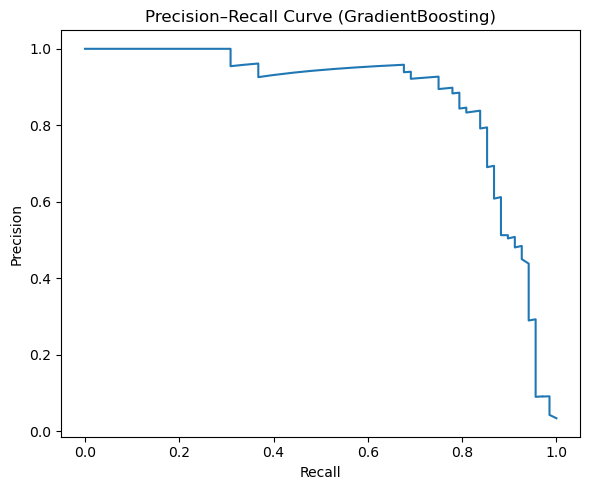

In [13]:
# Import precision-recall curve function
from sklearn.metrics import precision_recall_curve

# Compute precision and recall values
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

# Plot Precision–Recall curve
plt.figure(figsize=(6, 5))
plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve ({best_name})")

plt.tight_layout()
plt.show()

In [14]:
# Import precision-recall curve function again
from sklearn.metrics import precision_recall_curve

# Compute precision-recall values
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

# Define target recall level
target_recall = 0.80

# Find threshold closest to desired recall
idx = np.argmin(np.abs(recall - target_recall))

# Determine optimal probability threshold
optimal_threshold = thresholds[idx]

# Print threshold and performance
print("Chosen Threshold:", optimal_threshold)
print("Recall at threshold:", recall[idx])
print("Precision at threshold:", precision[idx])

Chosen Threshold: 0.3800069723236998
Recall at threshold: 0.7941176470588235
Precision at threshold: 0.84375


## 10. Confusion Matrix & Classification Report (Custom Threshold)

The confusion matrix at the selected threshold shows the trade-off between:
- catching failures (recall)
- minimizing false alarms (precision)

This evaluation validates that the chosen decision threshold produces operationally realistic outcomes.


In [15]:
# Import confusion matrix and classification report tools
from sklearn.metrics import confusion_matrix, classification_report

# Apply custom threshold to predictions
y_pred_custom = (y_scores >= optimal_threshold).astype(int)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_custom)

# Display confusion matrix
cm

Out[15]: 
array([[1922,   10],
       [  14,   54]])


In [16]:
# Print classification report with precision, recall, and F1 scores
print(classification_report(y_test, y_pred_custom))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.84      0.79      0.82        68

    accuracy                           0.99      2000
   macro avg       0.92      0.89      0.91      2000
weighted avg       0.99      0.99      0.99      2000



## 11. Risk Tiering (Low / Medium / High)

Instead of only a binary failure prediction, risk tiering provides a more realistic maintenance workflow:

- **High Risk:** immediate priority for maintenance action  
- **Medium Risk:** inspection / scheduled maintenance  
- **Low Risk:** normal operation  

This approach supports operational scheduling and aligns with the platform requirements.


In [17]:
# Define thresholds for risk tiers
HIGH_RISK_THRESHOLD = float(optimal_threshold)
MEDIUM_RISK_THRESHOLD = 0.10

# Create dataframe with predicted probabilities and assigned risk tiers
risk_predictions = pd.DataFrame({
    "probability": y_scores,
    "tier": [risk_tier(p, HIGH_RISK_THRESHOLD, MEDIUM_RISK_THRESHOLD) for p in y_scores],
    "actual": y_test.values
})

# Display number of machines in each risk tier
risk_predictions["tier"].value_counts()

Out[17]: 
tier
Low Risk       1903
High Risk        64
Medium Risk      33
Name: count, dtype: int64


## 12. Baseline Model Artifact

The baseline model is **not saved from this notebook**.
All model artifacts are generated centrally by `src/train.py`:

```
python -m src.train
```

This produces `best_model.pkl` (Soft Voting ensemble), `rul_regressor.joblib`,
and `threshold.json`. The baseline Gradient Boosting results documented above
serve as the performance floor that the ensemble improves upon.


In [18]:
# Model saving is handled by src/train.py
# This notebook only documents which baseline model performed best

print(f"Best baseline model: {best_name}")
print(f"PR-AUC: {results_df.iloc[0]['pr_auc']}")
print()

# Instructions for generating deployment models
print("To generate deployment models, run:  python -m src.train")

Best baseline model: GradientBoosting
PR-AUC: 0.8691883712500439

To generate deployment models, run:  python -m src.train


## Final Summary

- **Best Baseline Model:** Gradient Boosting (PR-AUC ~0.87, Recall ~0.76 at 0.5 threshold)
- **Engineered Features:** `Temp_diff` and `Torque_RPM_ratio` improved PR-AUC and reduced false positives
- **Threshold Exploration:** Initial threshold tuned to achieve ~0.80 recall — refined further in notebook 07
- **Risk Tiering:** Low / Medium / High tiers created for maintenance prioritisation
- **Next Step:** Notebook 07 builds ensemble models (Soft Voting, Stacking) that improve on these baselines

> The Soft Voting ensemble in notebook 07 achieves PR-AUC 0.8707 vs 0.8697 for standalone
> Gradient Boosting — a small but consistent improvement through model diversity.